In [11]:
import torch
from torchvision import datasets,transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt

In [2]:
#Define Transformation with data augemtation
transform_train = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32,padding =4),
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
])
transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
])
#Load Cifar10 dataset
train_dataset = datasets.CIFAR10(root='./data',train=True,download=True,transform=transform_train)
test_dataset = datasets.CIFAR10(root='./data',train=False,download=True,transform =transform_test)

train_loader = DataLoader(train_dataset,batch_size=64,shuffle=True)
test_loader = DataLoader(test_dataset,batch_size=64,shuffle=False)
print(f"Training Data size :{len(train_dataset)}")
print(f"Test Dataset Size:{len(test_dataset)}")

100%|██████████| 170M/170M [42:28<00:00, 66.9kB/s]


Training Data size :50000
Test Dataset Size:10000


In [7]:
#Define CNN model
class enhanced_CNN(nn.Module):
  def __init__(self):
    super(enhanced_CNN,self).__init__()
    self.conv1 = nn.Conv2d(3,6,5)
    self.bn1 = nn.BatchNorm2d(6)
    self.conv2 =nn.Conv2d(6,16,5)
    self.bn2 = nn.BatchNorm2d(16)
    self.pool = nn.MaxPool2d(2,2)
    self.dropout = nn.Dropout(0.5)
#To calculate the output layer from conv layers dynamically
    self._calculate_conv_output()
    self.fc1 = nn.Linear(self.conv_output_size,120)
    self.fc2 = nn.Linear(120,84)
    self.fc3 = nn.Linear(84,10)
  def _calculate_conv_output(self):
    #Dummy input sensor with the same size of the input images
    dummy_input = torch.zeros(1,3,32,32)
    with torch.no_grad():
      output = self.pool(F.relu(self.bn2(self.conv2(F.relu(self.bn1(self.conv1(dummy_input)))))))
    self.conv_output_size = output.numel()
  # Define forward function
  def forward(self,x):
    x = F.relu(self.bn1(self.conv1(x)))
    x = self.pool(F.relu(self.bn2(self.conv2(x))))
    x = x.view(x.size(0),-1)
    x = F.relu(self.fc1(x))
    x = self.dropout(x)
    x = F.relu(self.fc2(x))
    x = self.fc3(x)
    return x

model = enhanced_CNN()
print (model)

enhanced_CNN(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (bn1): BatchNorm2d(6, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (bn2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=2304, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)


In [10]:
#Define Loss Function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(),lr = 0.001)
training_loss = []
#def training loop

def train_model(model,train_loader,criterion,optimizer,epochs=20):
  model.train()
  for epoch in range (epochs):
    running_loss = 0.0
    for image,label in train_loader:
      optimizer.zero_grad()
      output = model(image)
      loss = criterion(output,label)
      loss.backward()
      optimizer.step()
      running_loss += loss.item()
    epoch_loss = running_loss/len(train_loader)
    training_loss.append(epoch_loss)
    print(f"Epochs : {epoch+1}, Loss :{epoch_loss:.4f}")

train_model(model,train_loader,criterion,optimizer)

#Evaluation loop
def evaluate_model (model,test_loader):
  model.eval()
  correct = 0
  total = 0
  with torch.no_grad():
    for images,labels in test_loader:
      outputs = model(images)
      _, predicted = torch.max(outputs,1)
      total += labels.size(0)
      correct += (predicted == labels).sum().item()
  print(f"Test Accuracy :{100* correct/total :.2f}%")
evaluate_model(model,test_loader)


Epochs : 1, Loss :1.7857
Epochs : 2, Loss :1.6048
Epochs : 3, Loss :1.5292
Epochs : 4, Loss :1.4759
Epochs : 5, Loss :1.4225
Epochs : 6, Loss :1.3888
Epochs : 7, Loss :1.3543
Epochs : 8, Loss :1.3446
Epochs : 9, Loss :1.3204
Epochs : 10, Loss :1.3074
Epochs : 11, Loss :1.2962
Epochs : 12, Loss :1.2776
Epochs : 13, Loss :1.2710
Epochs : 14, Loss :1.2688
Epochs : 15, Loss :1.2540
Epochs : 16, Loss :1.2467
Epochs : 17, Loss :1.2372
Epochs : 18, Loss :1.2354
Epochs : 19, Loss :1.2321
Epochs : 20, Loss :1.2212
Test Accuracy :62.57%


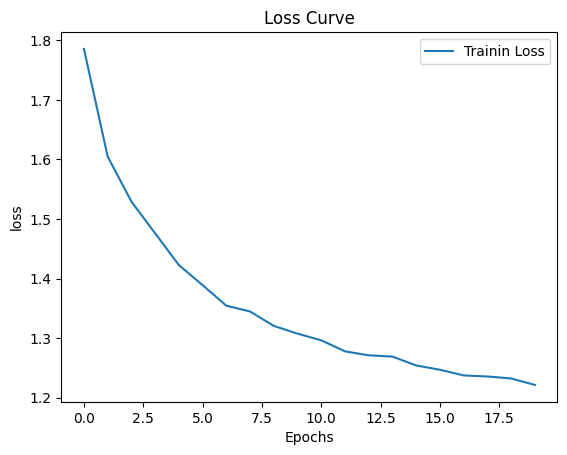

In [12]:
#Ploting the Loss and accuracy
plt.plot(training_loss ,label='Trainin Loss')
plt.title('Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('loss')
plt.legend()
plt.show()